<a href="https://colab.research.google.com/github/gpugovka/drones/blob/main/Drone_HW_Anomaly_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kinematics-Based UAV Telemetry Fault Detection Using Tree Ensembles

**Project Links:**
* **GitHub Repository:** `https://github.com/gpugovka/drones`
* **Kaggle Notebook:** `https://www.kaggle.com/code/erinbe/drone-hw-anomaly-detection-kinematics-trees`
* **Dataset:** [TLMUAV Anomaly Detection Datasets](https://www.kaggle.com/datasets/luyucwnu/tlmuav-anomaly-detection-datasets) (standalone dataset without an active competition leaderboard).
* **Illustration:** Kinematics & Attitude Reference: Beard, R. W., & McLain, T. W. (2012). Small Unmanned Aircraft: Theory and Practice[cite: 6]. Princeton University Press.

## License & Citing This Work
The original code, feature engineering, and analysis in this notebook are licensed under the **MIT License** (see the [LICENSE](https://github.com/gpugovka/drones/blob/main/LICENSE) file in the GitHub repository for full terms and third-party media exclusions).

If you use or reference this notebook, code, or methodology in your work, you must retain the copyright notice and cite it as follows:

* **Author:** Erin B. (2026)
* **Title:** Kinematics-Based UAV Telemetry Fault Detection Using Tree Ensembles
* **Repository:** [https://github.com/gpugovka/drones](https://github.com/gpugovka/drones)

## About this Dataset
This is a UAV anomaly detection dataset based on a software-in-the-loop simulation environment containing UAV anomaly logs.
* **Dataset Reference:** [https://doi.org/10.3390/app13074301](https://doi.org/10.3390/app13074301)

`Fusion_Data.csv` is a TLM dataset processed by a multi-sensor data fusion technique.
* **Fusion Data Reference:** [https://doi.org/10.1016/j.engappai.2024.107961](https://doi.org/10.1016/j.engappai.2024.107961)

Let's load datasets directly from Kaggle using their recommended code snippet.

In [12]:
import kagglehub

# Download latest version
dir_path = kagglehub.dataset_download("luyucwnu/tlmuav-anomaly-detection-datasets")
print("Path to dataset files:", dir_path)

100%|██████████| 4.48M/4.48M [00:00<00:00, 75.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/luyucwnu/tlmuav-anomaly-detection-datasets/versions/1


Import the necessary libraries and frameworks.

In [13]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## Data Files Inspection
Let's inspect what was loaded and locate the necessary data file with fused sensors data.

In [14]:
import os

for dirname, _, filenames in os.walk(dir_path):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/root/.cache/kagglehub/datasets/luyucwnu/tlmuav-anomaly-detection-datasets/versions/1/dataset/Fusion_Data.csv
/root/.cache/kagglehub/datasets/luyucwnu/tlmuav-anomaly-detection-datasets/versions/1/dataset/BARO/ALL_FAIL_LOG_BARO.csv
/root/.cache/kagglehub/datasets/luyucwnu/tlmuav-anomaly-detection-datasets/versions/1/dataset/CTUN/ALL_FAIL_LOG_CTUN.csv
/root/.cache/kagglehub/datasets/luyucwnu/tlmuav-anomaly-detection-datasets/versions/1/dataset/ATT/ALL_FAIL_LOG_ATT.csv
/root/.cache/kagglehub/datasets/luyucwnu/tlmuav-anomaly-detection-datasets/versions/1/dataset/PSCD/ALL_FAIL_LOG_PSCD.csv
/root/.cache/kagglehub/datasets/luyucwnu/tlmuav-anomaly-detection-datasets/versions/1/dataset/MOTB/ALL_FAIL_LOG_MOTB.csv
/root/.cache/kagglehub/datasets/luyucwnu/tlmuav-anomaly-detection-datasets/versions/1/dataset/MAG/ALL_FAIL_LOG_MAG_0.csv
/root/.cache/kagglehub/datasets/luyucwnu/tlmuav-anomaly-detection-datasets/versions/1/dataset/GPS/ALL_FAIL_LOG_GPS_0.csv
/root/.cache/kagglehub/datasets/luyucwnu/tlmu

The downloaded folder contains 17 CSV files total organized into subfolders by individual UAV sensors: `GPS`, `IMU`, `MAG`, `BARO`, `BAT`, `ATT`, `RATE`, and `VIBE`, along with `Fusion_Data.csv` in the root `dataset/` directory.

We use `Fusion_Data.csv` because it already combines and synchronizes the multi-sensor telemetry logs into a single table ready for classification.

Now let's load the fused sensors dataset and show a few top rows.

In [15]:
fused_data_path = os.path.join(dir_path, "dataset/Fusion_Data.csv")

df = pd.read_csv(fused_data_path)
df.head()

,timestamp,DesRoll,Roll,DesPitch,Pitch,DesYaw,Yaw,ErrRP,ErrYaw,MagX,MagY,MagZ,abGyrX,abGyrY,abGyrZ,abAccX,abAccY,abAccZ,labels
0,15363852.0,0.0,0.02,0.0,0.0,3.510,3.510,0.0,0.0,232.0,52.0,52.0,0.000136,0.000135,0.000232,-0.000463,-0.001343,-9.817147,0
1,15413832.0,0.0,0.02,0.0,0.0,3.525,3.525,0.0,0.0,232.0,52.0,52.0,0.000165,0.000150,0.000228,-0.000523,-0.000192,-9.816688,0
2,15463812.0,0.0,0.02,0.0,0.0,3.540,3.540,0.0,0.0,232.0,52.0,52.0,0.000167,0.000211,0.000274,-0.001630,-0.000446,-9.816650,0
3,15463812.0,0.0,0.02,0.0,0.0,3.540,3.540,0.0,0.0,232.0,52.0,52.0,0.000174,0.000171,0.000216,-0.001502,0.000013,-9.817536,0
4,15513792.0,0.0,0.02,0.0,0.0,3.550,3.550,0.0,0.0,232.0,52.0,52.0,0.000204,0.000242,0.000255,-0.002186,-0.002237,-9.816851,0


Inspecting rows, column features and missing data.

In [16]:
df.shape

(12253, 19)

In [17]:
df.columns

Index(['timestamp', 'DesRoll', 'Roll', 'DesPitch', 'Pitch', 'DesYaw', 'Yaw',
       'ErrRP', 'ErrYaw', 'MagX', 'MagY', 'MagZ', 'abGyrX', 'abGyrY', 'abGyrZ',
       'abAccX', 'abAccY', 'abAccZ', 'labels'],
      dtype='object')

## Dataset Overview & Features

The `Fusion_Data.csv` dataset contains **12,253 rows and 19 columns** of UAV telemetry logs collected from a software-in-the-loop simulation environment.

**Input Features (18):**
* `timestamp`: Simulation log timestamp (in microseconds).
* `DesRoll`, `DesPitch`, `DesYaw`: Desired attitude angles commanded by the flight controller.
* `Roll`, `Pitch`, `Yaw`: Actual measured UAV attitude angles.
* `ErrRP`, `ErrYaw`: Attitude tracking errors for roll, pitch and yaw.
* `MagX`, `MagY`, `MagZ`: 3-axis magnetometer readings.
* `abGyrX`, `abGyrY`, `abGyrZ`: 3-axis gyroscope angular velocity readings.
* `abAccX`, `abAccY`, `abAccZ`: 3-axis accelerometer readings.

**Target Variable:**
* `labels`: Multi-class fault indicator.

The four common faults of UAVs are:
* GPS fault
* accelerometer fault
* engine fault
* Remote-Control System fault.

From Beard, R. W., & McLain, T. W. (2012). Small Unmanned Aircraft: 
Theory and Practice. Princeton University Press.


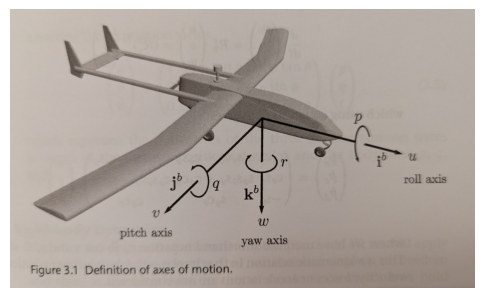

In [18]:
import urllib.request
from PIL import Image
import numpy as np

print("From Beard, R. W., & McLain, T. W. (2012). Small Unmanned Aircraft: \n"
"Theory and Practice. Princeton University Press.")

url = "https://raw.githubusercontent.com/gpugovka/drones/main/attitude_angles.jpg"
img = np.array(Image.open(urllib.request.urlopen(url)))

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

## Modeling Approach
We formulate this as a **multi-class classification problem**: `0` = Normal, `1` = GPS fault, `2` = Accelerometer fault, `3` = Engine fault, `4` = RC fault.

As a part of data pre-processing we remove timestamp column to prevent time-based memorization of the fault state. We also analyze the parameters as a part of conceptual physical kinematics model, which allows us to engineer several features of physical meaning, as well as sensor error indicator.

Next we use and compare three supervised ML models:

### Hyperparameter Tuning & Cross-Validation Details

#### 1. Logistic Regression (`LogisticRegressionCV`)
* **Approach:** A linear baseline utilizing `class_weight='balanced'` and cross-validation with hyperparameter tuning.
* **Parameters Tuned:** We tune the inverse of regularization strength, denoted as **`C`**. Smaller values of `C` specify stronger regularization (penalizing large coefficients to prevent overfitting), while larger values reduce regularization. We use `Cs=10` to test 10 logarithmically spaced values automatically.
* **Under the Hood:** Instead of doing a manual grid search, `LogisticRegressionCV` computes the regularization path efficiently. It splits `X_train` into 5 folds (`cv=5`), trains the model on 4 folds across all 10 candidate `C` values, and validates on the 5th fold. It automatically selects the optimal `C` value that yields the highest average validation score across all folds, and then refits the final model on the entire training set using that best parameter.

#### 2. Random Forest (`RandomForestClassifier`)
* **Approach:** A non-linear decision tree ensemble method using bagging to build multiple trees independently in parallel, configured with `class_weight='balanced'` to handle class imbalance.
* **Parameters Tuned (Default behavior):** Out-of-the-box, the standard `RandomForestClassifier` relies on default scikit-learn hyperparameters (e.g., `n_estimators=100` trees, `max_depth=None` allowing trees to expand fully).
* **Under the Hood:** While we instantiated it with default settings rather than an explicit `GridSearchCV`, Random Forest natively performs its own implicit cross-validation during training via **Bootstrap Aggregating (Bagging)**. For every individual tree in the forest, scikit-learn draws a random sample of the training data with replacement (leaving out about 36% of the data as "Out-of-Bag" or OOB samples). Each tree is trained independently in parallel (`n_jobs=-1`), and its internal quality is implicitly validated against its respective OOB data, making the ensemble highly robust to overfitting without requiring manual cross-validation loops.

#### 3. XGBoost Classifier (`XGBClassifier`)
* **Approach:** A non-linear decision tree ensemble using gradient boosting to build trees sequentially, where each new tree specifically focuses on correcting the errors of previous ones.
* **Parameters Tuned (Default behavior):** Uses default gradient boosting hyperparameters (e.g., `n_estimators=100`, `max_depth=6`, and a default learning rate).
* **Under the Hood:** XGBoost trains its decision trees **sequentially (boosting)**. It calculates the errors of the first tree, and constructs the second tree specifically to predict and correct those errors. This iterative boosting process continues step-by-step up to the maximum number of estimators. Because it weights subsequent trees based on previous performance, it minimizes bias and variance simultaneously across the training data.

## Exploratory Data Analysis

Starting from analysis of the missing data.

In [19]:
df.isna().sum()

,0
timestamp,0
DesRoll,0
Roll,0
DesPitch,0
Pitch,0
DesYaw,0
Yaw,0
ErrRP,0
ErrYaw,0
MagX,0


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12253 entries, 0 to 12252
Data columns (total 19 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  12253 non-null  float64
 1   DesRoll    12253 non-null  float64
 2   Roll       12253 non-null  float64
 3   DesPitch   12253 non-null  float64
 4   Pitch      12253 non-null  float64
 5   DesYaw     12253 non-null  float64
 6   Yaw        12253 non-null  float64
 7   ErrRP      12253 non-null  float64
 8   ErrYaw     12253 non-null  float64
 9   MagX       12253 non-null  float64
 10  MagY       12253 non-null  float64
 11  MagZ       12253 non-null  float64
 12  abGyrX     12253 non-null  float64
 13  abGyrY     12253 non-null  float64
 14  abGyrZ     12253 non-null  float64
 15  abAccX     12253 non-null  float64
 16  abAccY     12253 non-null  float64
 17  abAccZ     12253 non-null  float64
 18  labels     12253 non-null  int64  
dtypes: float64(18), int64(1)
memory usage: 1.8 MB


The data is likely already processed for missing data, so nothing is needed to do about that.

Next let's check summary statistics, extreme sensor values, and duplicate rows with the same timestamp.

In [21]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df['timestamp'].duplicated().sum())

# Setting for more readable output of floating points (4 fpt).
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

df.describe().T[['min', 'mean', '50%', 'max', 'std']]

Duplicate rows: 0
Duplicate timestamps: 4084


,min,mean,50%,max,std
timestamp,15363852.0000,235211166.5893,235763990.0000,439963944.0000,118894196.1837
DesRoll,-29.9900,-0.7341,-0.1600,29.9900,10.1980
Roll,-32.0600,0.7348,0.1800,114.8100,11.6208
DesPitch,-29.9900,-7.7472,-0.5400,29.7100,14.6209
Pitch,-33.0300,-7.9927,-0.5300,60.3500,14.6852
DesYaw,0.5400,183.0617,147.6800,357.9100,113.9488
Yaw,0.3300,181.9708,147.4100,359.0700,113.3485
ErrRP,0.0000,0.1003,0.0000,0.9400,0.1881
ErrYaw,0.0000,0.1003,0.0000,0.9400,0.1881
MagX,-468.0000,-41.0030,-29.0000,517.0000,213.2473


### Data Quality & Outlier Analysis

* **Duplicates:** There are no exact duplicate rows, but `4,084` rows share duplicate timestamps with slightly different sensor readings, which is likely the result of fusing logs from multiple sensors. All rows are retained.
* **Redundant Columns:** `ErrRP` and `ErrYaw` have identical values across the dataset (mean `0.1003`, max `0.94`), as do `MagY` and `MagZ` (mean `-22.0146`, min `-552.0`, max `440.0`). We keep `MagX`, `MagY`, and `MagZ` temporarily to compute the 3D magnetic field magnitude, and then drop the raw single-axis columns and `ErrYaw` before training to avoid collinearity.
* **Outliers:** Extreme values appear in sensor columns such as `abAccZ` (min `-88.01` vs. median `-9.80`) and `Roll` (max `114.81` vs. median `0.18`). Because these spikes correspond to physical fault states rather than data entry errors, they are preserved as informative signals for the model.

**Labels Analysis**

Label 0 a normal state;

Label 1 the GPS anomaly;

Label 2 the accelerometer anomaly;

Label 3 the engine anomaly;

Label 4 the RC anomaly.

In [22]:
df['labels'].unique()

array([0, 1, 2, 3, 4])

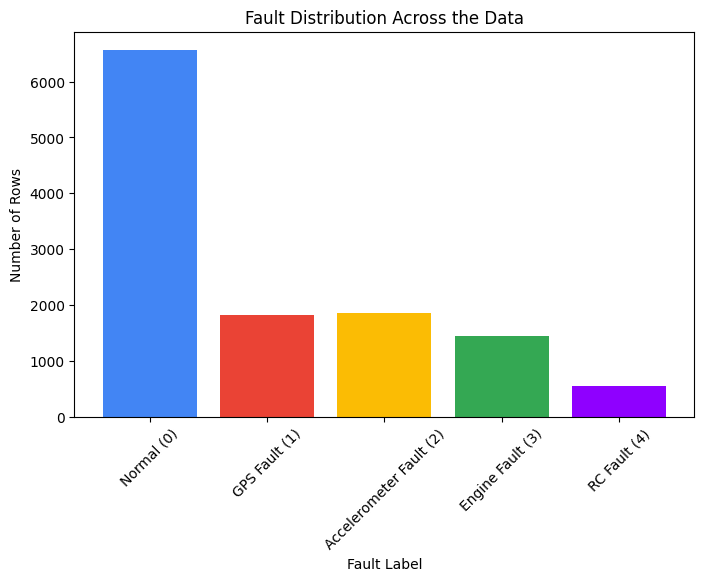

In [23]:
import matplotlib.pyplot as plt

test_df = df

label_counts = test_df['labels'].value_counts().sort_index()
categories = ['Normal (0)', 'GPS Fault (1)', 'Accelerometer Fault (2)', 'Engine Fault (3)', 'RC Fault (4)']
counts = [label_counts.get(i, 0) for i in range(5)]

plt.figure(figsize=(8, 5))
plt.bar(categories, counts, color=['#4285F4', '#EA4335', '#FBBC04', '#34A853', '#8F00FF'])
plt.title('Fault Distribution Across the Data')
plt.xlabel('Fault Label')
plt.ylabel('Number of Rows')
plt.xticks(rotation=45)
plt.show()

**Observation:**

The dataset is imbalanced — over half of the logs represent normal flight, while errors, especially RC fault, have a way less samples. Using `class_weight='balanced'` during training will help prevent the models from ignoring minority fault classes.

### Preventing memorization based on time
Removing `timestamp` can help to avoid time-based memorization.

Dropping the columns that don't contribute physical meaning to the model and can potentially cause the model to memorize the time from the training data set rather than focus on the physical features and as a result overfit with memorization.

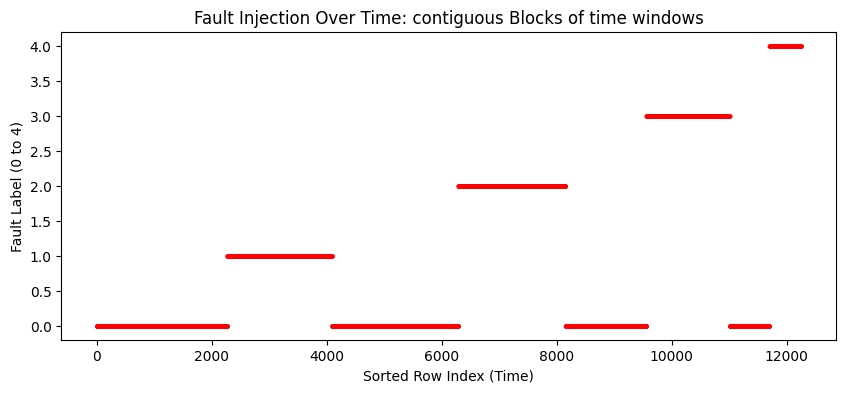

In [24]:
# Sort the dataset by timestamp to check if faults occur in discrete time blocks
df_sorted = df.sort_values(by="timestamp")

# Plot target labels against sorted row index (time)
plt.figure(figsize=(10, 4))
plt.scatter(
    range(len(df_sorted)), df_sorted["labels"], alpha=0.3, s=5, c="red"
)
plt.title(
    "Fault Injection Over Time: contiguous Blocks of time windows"
)
plt.xlabel("Sorted Row Index (Time)")
plt.ylabel("Fault Label (0 to 4)")
plt.show()

However even with `timestamp` removed the data are taking from a very close consequent time ranges of a flight, and as a result using these raw data can attribute to memorization of the training data rather than learning physical model patterns. To avoid that we propose transition to a kinematic based model built using the raw data.

## Physics-Based Feature Engineering
To capture UAV flight dynamics better than raw single-axis readings, we add six physics features:
* **3D Acceleration Magnitude:** Combines all three accelerometer axes into total specific force:
  $$a_{total} = \sqrt{(abAccX^2 + abAccY^2 + abAccZ^2)}$$
* **3D Angular Velocity Magnitude:** Measures total rotational rate across all three gyroscope axes:
  $$\omega_{total} = \sqrt{(abGyrX^2 + abGyrY^2 + abGyrZ^2)}$$
* **Total Magnetic Field Strength (Magnitude)** Measures overall strength of the ambient magnetic field experienced by the drone. Sudden spikes, drops, or distortions in the total magnetic magnitude can signal hardware malfunctions, sensor interference, or external magnetic anomalies (which often correlate with compass errors or navigation faults).
$$MagneticField_{total,local} = \sqrt{(MagX^2 + MagY^2 + MagZ^2)}$$

Combining the three axes into a single magnitude for the three features above provides a rotation-invariant scalar that represents the strength rather than specific point of data that is risky for memorization.

* **Attitude Tracking Errors:** Measures the difference between commanded and actual angles to capture control issues during hardware or RC faults. Because yaw angles span $[0^\circ, 360^\circ]$, we apply modular wrapping to compute the shortest angular difference within $[-180^\circ, 180^\circ]$ and avoid false $360^\circ$ spikes when crossing North.

$$Error_{Roll} = \text{DesRoll} - \text{Roll}$$

$$Error_{Pitch} = \text{DesPitch} - \text{Pitch}$$

$$Error_{Yaw} = ((\text{DesYaw} - \text{Yaw} + 180) \bmod 360) - 180$$



In [25]:
# Adding Physics features:
# 3D Acceleration Magnitudes
df['acceleration'] = np.sqrt(df['abAccX']**2 + df['abAccY']**2 + df['abAccZ']**2)

# Angular Velocity Magnitudes
df['angular_velocity'] = np.sqrt(df['abGyrX']**2 + df['abGyrY']**2 + df['abGyrZ']**2)

# Magnetic Field Magnitudes
df['magnetic_field'] = np.sqrt(df['MagX']**2 + df['MagY']**2 + df['MagZ']**2)

# Attitude Errors
df['roll_error'] = df['DesRoll'] - df['Roll']
df['pitch_error'] = df['DesPitch'] - df['Pitch']
df['yaw_error'] = (df['DesYaw'] - df['Yaw'] + 180) % 360 - 180

Let's perform a feature correlation audit to understand how each feature correlates with the target.

In [26]:
print(df.corr()['labels'].sort_values(ascending=False))

labels              1.0000
timestamp           0.5470
DesPitch            0.2657
DesYaw              0.2601
Yaw                 0.2575
ErrYaw              0.2404
ErrRP               0.2404
Pitch               0.2246
MagY                0.1878
MagZ                0.1878
pitch_error         0.1325
acceleration        0.1292
MagX                0.0967
yaw_error           0.0937
Roll                0.0598
angular_velocity    0.0588
abGyrX              0.0167
abAccX             -0.0011
abGyrY             -0.0264
magnetic_field     -0.0318
abGyrZ             -0.0537
DesRoll            -0.0707
abAccZ             -0.1321
roll_error         -0.2125
abAccY             -0.2969
Name: labels, dtype: float64


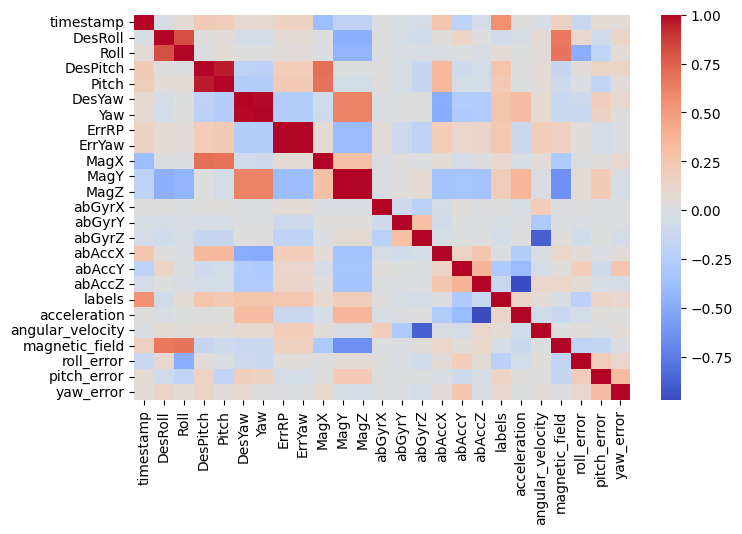

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(), annot=False, cmap='coolwarm')
plt.show()

**Correlation Analysis**

* **Target Correlations (`labels`):** Among the 7 selected physical features, attitude tracking errors show the strongest linear relationships with the fault labels: `ErrRP` ($r = 0.2404$) and `roll_error` ($r = -0.2125$), followed by `pitch_error` ($r = 0.1325$) and `acceleration` ($r = 0.1292$). `yaw_error` ($r = 0.0937$), `angular_velocity` ($r = 0.0588$), and `magnetic_field` ($r = -0.0318$) have a weaker linear correlations with `labels`, indicating that their relationship to specific fault types is non-linear, which makes sense for the physical nature of these values.
* **Feature Independence:** Dropping the raw single-axis readings and redundant columns (`ErrYaw`, `MagX`, `MagY`, `MagZ`) eliminates exact collinearity. The remaining 7 kinematic magnitudes and attitude tracking errors exhibit low pairwise correlation, providing independent physical signals for classification.

## Dropping Non-Physical and Redundant Columns

In [28]:
selected_cols = ['ErrRP', 'acceleration', 'angular_velocity', 'magnetic_field', 'roll_error', 'pitch_error', 'yaw_error', 'labels']
df = df[selected_cols]

labels              1.0000
ErrRP               0.2404
pitch_error         0.1325
acceleration        0.1292
yaw_error           0.0937
angular_velocity    0.0588
magnetic_field     -0.0318
roll_error         -0.2125
Name: labels, dtype: float64


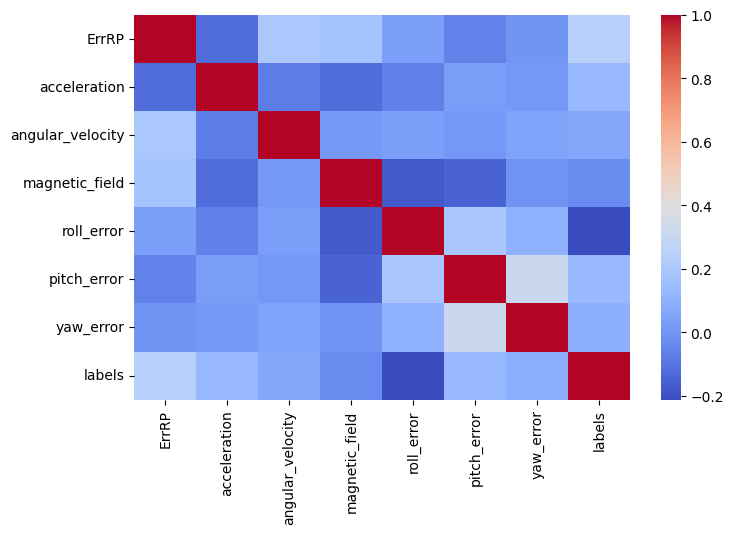

In [29]:
print(df.corr()['labels'].sort_values(ascending=False))

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(), annot=False, cmap='coolwarm')
plt.show()

## Data Preparation
* **Categorical Encoding:** Not required because all input features are continuous numerical sensor readings.
* **Feature Scaling:** Applied `StandardScaler` fit_transform only on `X_train` and transformed `X_test` without fitting to prevent data leakage and ensure proper convergence for Logistic Regression.

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = df.drop(columns=['labels'])
y = df['labels']

Performing a 80/20 train-test split for evaluating on the unseen data.

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=102, shuffle=True)

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Modeling with Logistic Regression

In [32]:
from sklearn.linear_model import LogisticRegressionCV

logr_model = LogisticRegressionCV(
    Cs=10,                      # Tests 10 values of C logarithmically spaced
    cv=5,                       # 5-fold cross-validation
    class_weight='balanced',
    max_iter=1000,
    random_state=102,
    n_jobs=-1
)
logr_model.fit(X_train, y_train)

LogisticRegressionCV(class_weight='balanced', cv=5, max_iter=1000, n_jobs=-1,
                     random_state=102)

In [33]:
from sklearn.metrics import accuracy_score, classification_report
logr_model.score(X_test, y_test)

logr_test_pred = logr_model.predict(X_test)
print("Metrics for the Test set:")
print(classification_report(y_test, logr_test_pred))
logr_test_accuracy = accuracy_score(y_test, logr_test_pred)
print("Accuracy: ", logr_test_accuracy)

Metrics for the Test set:
              precision    recall  f1-score   support

           0       0.94      0.56      0.70      1324
           1       0.52      0.89      0.65       340
           2       0.84      0.92      0.88       387
           3       0.81      0.94      0.87       300
           4       0.26      0.78      0.39       100

    accuracy                           0.72      2451
   macro avg       0.67      0.82      0.70      2451
weighted avg       0.82      0.72      0.73      2451

Accuracy:  0.7172582619339045


## Modeling with Random Forest Classifier

Train Random Forest and evaluate

In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score


rf = RandomForestClassifier(class_weight='balanced', random_state=102, n_jobs=-1)
rf.fit(X_train, y_train)

rf_test_preds = rf.predict(X_test)
print("Metrics for the Test set:")
print(classification_report(y_test, rf_test_preds))
rf_test_accuracy = accuracy_score(y_test, rf_test_preds)
print("Random Forest Test Accuracy:", rf_test_accuracy)

Metrics for the Test set:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1324
           1       1.00      0.98      0.99       340
           2       0.99      1.00      0.99       387
           3       1.00      1.00      1.00       300
           4       0.99      0.88      0.93       100

    accuracy                           0.99      2451
   macro avg       0.99      0.97      0.98      2451
weighted avg       0.99      0.99      0.99      2451

Random Forest Test Accuracy: 0.9893920848633211


## Modeling with XGBoost Classifier

In [35]:
from xgboost import XGBClassifier

# XGBoost automatically handles multi-class if labels are 0-indexed (which yours are)
xgb = XGBClassifier(random_state=102, n_jobs=-1)
xgb.fit(X_train, y_train)

xgb_test_preds = xgb.predict(X_test)
print("Metrics for the Test set:")
print(classification_report(y_test, xgb_test_preds))
xgb_test_accuracy = accuracy_score(y_test, xgb_test_preds)
print("XGB Test Accuracy:", xgb_test_accuracy)

Metrics for the Test set:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1324
           1       0.99      0.99      0.99       340
           2       0.99      1.00      1.00       387
           3       1.00      1.00      1.00       300
           4       1.00      0.94      0.97       100

    accuracy                           0.99      2451
   macro avg       1.00      0.98      0.99      2451
weighted avg       0.99      0.99      0.99      2451

XGB Test Accuracy: 0.9934720522235823


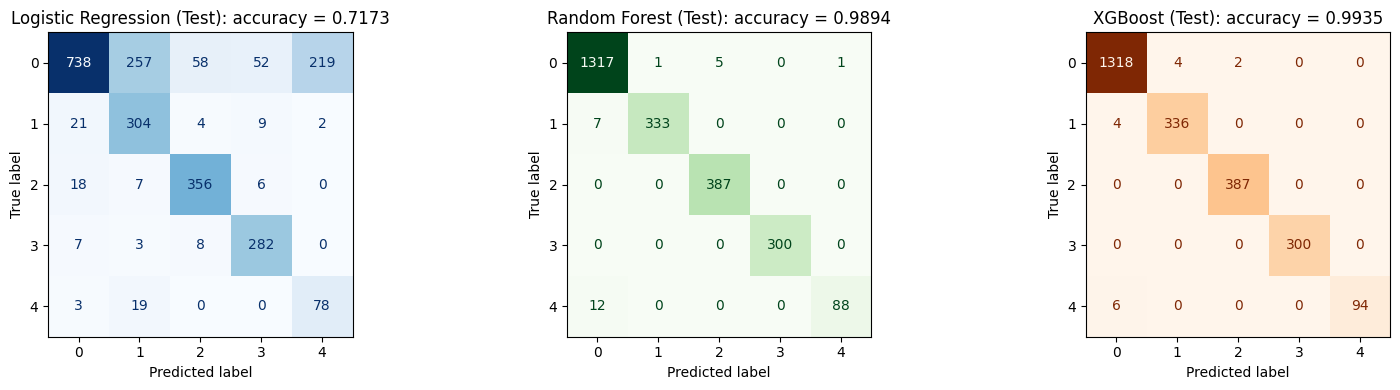

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Side-by-side Confusion Matrices on Test Set
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ConfusionMatrixDisplay.from_predictions(y_test, logr_test_pred, ax=axes[0], cmap='Blues', colorbar=False)
logr_test_title_str = 'Logistic Regression (Test): accuracy = ' + str(round(logr_test_accuracy, 4))
axes[0].set_title(logr_test_title_str)

ConfusionMatrixDisplay.from_predictions(y_test, rf_test_preds, ax=axes[1], cmap='Greens', colorbar=False)
rf_test_title_str = 'Random Forest (Test): accuracy = ' + str(round(rf_test_accuracy, 4))
axes[1].set_title(rf_test_title_str)

ConfusionMatrixDisplay.from_predictions(y_test, xgb_test_preds, ax=axes[2], cmap='Oranges', colorbar=False)
xgb_test_accuracy_str = 'XGBoost (Test): accuracy = ' + str(round(xgb_test_accuracy, 4))
axes[2].set_title(xgb_test_accuracy_str)

plt.tight_layout()
plt.show()

## Evaluation & Model Comparison

| Model | Test Accuracy |
| :--- | :---: |
| Logistic Regression (CV Tuned) | 71.73% |
| Random Forest | 98.94% |
| XGBoost | 99.35% |

**Results Interpretation:**
* **Overall Performance:** XGBoost and Random Forest significantly outperform Logistic Regression (99.35% and 98.94% vs. 71.73% test accuracy). Relying strictly on rotation-invariant physical magnitudes and tracking errors confirms that non-linear decision boundaries are necessary to isolate UAV fault dynamics.
* **Error Analysis and Confusion Matrices:** Logistic Regression generates 586 false positives on normal flight samples (`0`), frequently misclassifying them as GPS (`1`) and RC (`4`) faults. Random Forest and XGBoost eliminate nearly all false positives, making only 26 and 16 total mistakes respectively out of 2,451 test samples.